# Overlap, Outlier, Noise management

### <i> Using Autoencoder </i>

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("../diabetes.csv")
df

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,1,89,66,23,94,28.1,0.167,21,neg
1,0,137,40,35,168,43.1,2.288,33,pos
2,3,78,50,32,88,31.0,0.248,26,pos
3,2,197,70,45,543,30.5,0.158,53,pos
4,1,189,60,23,846,30.1,0.398,59,pos
...,...,...,...,...,...,...,...,...,...
387,0,181,88,44,510,43.3,0.222,26,pos
388,1,128,88,39,110,36.5,1.057,37,pos
389,2,88,58,26,16,28.4,0.766,22,neg
390,10,101,76,48,180,32.9,0.171,63,neg


---

### Using AutoEncoder -- Option A

### <i> Out-of-the-box `poyd.Autoencoder`


<i>EXPLANATION (As heuristic as possible) We can handle outliers, noise, and sometimes even overlap using an unorthodox (to me) method, `AutoEncoding`. This works via training a Neural Network to check for fits to see how 'unusual' each row is for each feature.

It then gives each row a score as to how strange the value is compared to others using that Neural Network system. 

This is my approach:


<Axes: xlabel='glucose', ylabel='mass'>

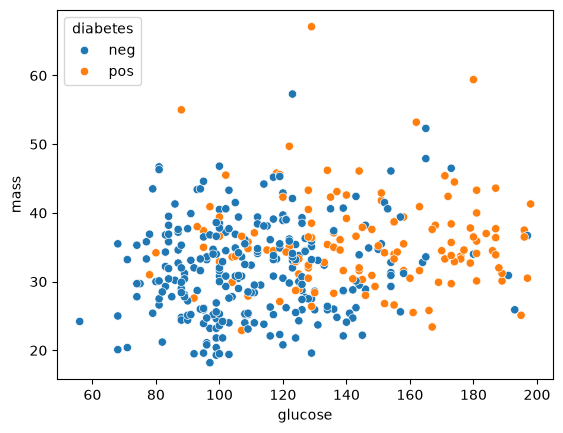

In [19]:
# Here is the same visual again. It has outliers, some noise, and overlap.
sns.scatterplot(df, x="glucose", y="mass", hue="diabetes")

In [20]:
# In this example, instead of making our own custom Neural network from scratch,
# we'll use a huge library framework called `pyod`, which actually
# has an AutoEncoder method for us just for this use case.

# pip install pyod
from pyod.models.auto_encoder import AutoEncoder
from sklearn.model_selection import train_test_split

# X,y split
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

model = AutoEncoder(
    # THE MOST IMPORTANT PARAMETER, `contamination`. This is you telling the 
    # model how much % of the dataset you expect to be outliers or noise.
    # You'll want to experiment with this (see the documentation link below
    # for extra parameters!)
    contamination=0.05,
    random_state=42
)

# Fit the AutoEncoder ONLY on the training data.
model.fit(X_train)

# Calculate anomaly scores for the training data.
train_anomaly_scores = model.decision_function(X_train)

# Calculate anomaly scores for the test data.
test_anomaly_scores = model.decision_function(X_test)

# Add the anomaly_scores into the dataframe
df["anomaly_score"] = np.nan
df.loc[X_train.index,"anomaly_score"] = train_anomaly_scores
df.loc[X_test.index,"anomaly_score"] = test_anomaly_scores

# Output the anomaly score results as a column in your original dataframe.
df["anomaly_score"]

# Viola. You now have a list of anomaly scores. 


Training: 100%|██████████| 10/10 [00:00<00:00, 58.36it/s]


0      0.875913
1      2.861892
2      1.464398
3      2.893278
4      3.603206
         ...   
387    2.401481
388    1.128044
389    1.314031
390    3.600315
391    0.992320
Name: anomaly_score, Length: 392, dtype: float64

In [21]:
# As you can see -- each row now has an anomaly score. And we can now choose 
# how much our cutoff is for that anomaly score that we want to permit. 

# IN OTHER WORDS: How much anomaly score should be considered before we just
# remove it entirely from the dataset?

# In this case, I'm using quantiles to filter them out.
df_autoencoded = df[
    (df['anomaly_score'] >= df['anomaly_score'].quantile(q=0.15)) &
    (df['anomaly_score'] <= df['anomaly_score'].quantile(q=0.85))
    ]


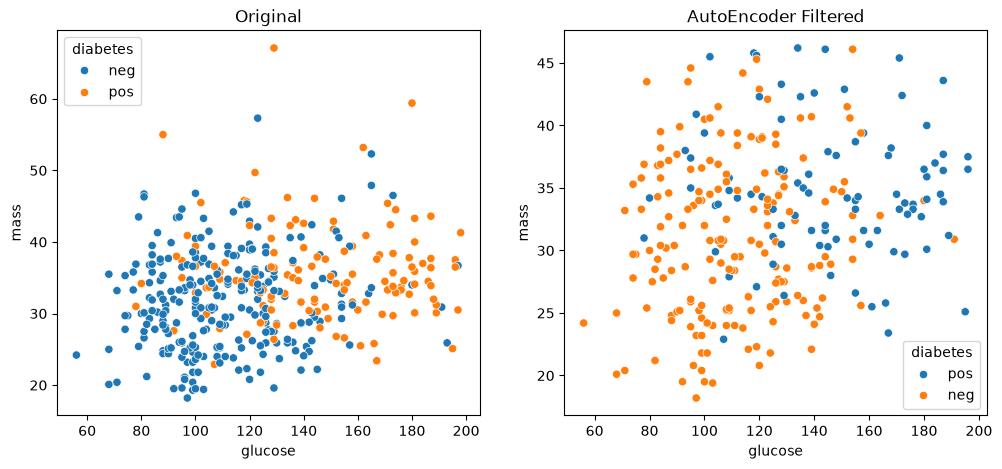

In [22]:
# Now, let's visualize. What did I change?
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(df, x="glucose", y="mass", hue="diabetes", ax=axes[0])
sns.scatterplot(df_autoencoded, x="glucose", y="mass", hue="diabetes")
# Prevents overlap between graphs
axes[0].set_title("Original")
axes[1].set_title("AutoEncoder Filtered")

# Shows the plots
plt.show()


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Observations</h3>

Notice the following:

* It got rid of the outliers in the dimensions. As a bi-product, it also sometimes gets rid of a small amount of overlap.

In the case of noise, `AutoEncoder` also would work in the sense of stuttering, where values JUMP up really high or low.

<strong> The primary advantage for `AutoEncoders` is that where instead of using IQR, and Z-score on a single column, `AutoEncoder` 
looks at the relationships of all the features combined instead of just one and checks them independently. </strong>

[Documentation](https://pyod.readthedocs.io/en/latest/pyod.models.tabular.html#pyod.models.auto_encoder.AutoEncoder)


<strong style='color:orange ; background-color:black;'>You have lots of options here, such as the number of epochs, batch size, number of neurons per hidden layers, batch normalization, etc.
 </strong>


I find this significantly easier to use out-of-the box. 

</div>

#### <strong style='color:red'> IF you're using this in a Pipeline, YOU MUST USE A  TRAIN, TEST split before using this method.</strong>

---

### Using AutoEncoder: Option B 

### <I> Using a custom Neural Network 

Sometimes, a simple neural network doesn't really work and you may want something more customized. In that case, you'd want to use Toumas' Neural network code snippet.
Just like before, Tuomas uses an auto-encoded dataframe to mask over the original dataset to determine which rows are anomalies, using `Keras`

Naturally, this is considerably more customizeable at the expense of the abstraction layer.

In [23]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np 

# Load the dataset
df = pd.read_csv("../diabetes.csv")
df


# scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [24]:
# pip install tensorflow
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# define the input dimension
# in this case 12 variables - target variable = 11
input_dim = X_train.shape[1]

# basically => we are reducing from original amount of variables
# into => 8 variables
encoding_dim = 10

input_layer = Input(shape=(input_dim,))

# encoder/decooder => autoencoder
# this is "the bottleneck" that reduces the amount of variables
encoded = Dense(encoding_dim, activation='relu')(input_layer)

# this version with only encode -> decode is called a Shallow AutoEncoder
# if you add more hidden layers => it's called => Deep AutoEncoder
# you can also use linear if your target is continuous => regression
decoded = Dense(input_dim, activation='sigmoid')(encoded)

# combine the layers above into a complete autoencoder
autoencoder = Model(inputs=input_layer, outputs=decoded)

# encoder model that reduces dimensionality
encoder = Model(inputs=input_layer, outputs=encoded)

# compile and train 
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.fit(X_train, X_train, epochs=50, batch_size = 32, shuffle=True, validation_split=0.2)

# apply the dimensionality reduction
X_train_encoded = encoder.predict(X_train)
X_test_encoded = encoder.predict(X_test)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1.2264 - val_loss: 1.2316
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.2132 - val_loss: 1.2188
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.2005 - val_loss: 1.2060
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1882 - val_loss: 1.1933
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1757 - val_loss: 1.1808
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.1634 - val_loss: 1.1684
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1510 - val_loss: 1.1561
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.1386 - val_loss: 1.1440
Epoch 9/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.1263 - val_loss: 1.1317
Epoch 10/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1140 - val_loss: 1.1194
Epoch 11/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1014 - val_loss: 1.1069
Epoch 12/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.0891 - val_loss: 1.0942
Epoch 13/5

In [25]:
# create a pandas DataFrame for easier inspection
num_components = X_train_encoded.shape[1]

# create a DataFrame
encoded_df = pd.DataFrame(X_train_encoded, columns=[f"Component {i + 1}" for i in range(num_components)])

# also add the target back
encoded_df['quality'] = y_train

# now we have similar components as in PCA
# but we have no idea of the loadings
# since we are using an autoencoder
# you can use SHAP/LIME or other tools 
# for estimating what affects what

# due to the lack of metrics, if the point is to optimize
# the dataset (reduce variable or noise etc.)
# consider using PCA, UMAP or Kernel PCA, based on 
# the type of dataset linear / non-linear
encoded_df

,Component 1,Component 2,Component 3,Component 4,Component 5,Component 6,Component 7,Component 8,Component 9,Component 10,quality
0,0.375700,0.873207,0.265935,1.510419,1.018835,0.530418,1.078560,0.644688,0.000000,0.000000,NaN
1,1.439434,0.191249,0.000000,0.000000,0.182292,0.585765,1.789616,1.421676,2.727709,2.089828,pos
2,4.039268,0.838868,0.203472,1.585119,1.085270,0.467005,0.000000,0.000000,0.000000,0.000000,pos
3,0.409648,0.000000,0.000000,0.000000,0.000000,0.662509,2.764946,1.150456,3.705010,2.267403,NaN
4,1.525554,0.745775,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.853801,0.641639,pos
...,...,...,...,...,...,...,...,...,...,...,...
308,0.000000,1.767576,3.000099,1.394950,0.035368,0.000000,0.000000,0.000000,0.000000,0.685566,neg
309,0.000000,0.473704,0.000000,2.030782,0.196881,1.524839,0.000000,0.537429,0.000000,0.000000,pos
310,0.000000,0.461456,1.030336,0.000000,0.000000,0.047612,0.262920,1.007764,1.397296,1.695619,pos
311,1.524726,3.818231,3.022197,2.555271,2.815707,0.194818,0.000000,0.241720,0.000000,0.000000,neg


<i> Here, you can see that the encoded distances determine for each column how much an anomaly that value for that row is. 

You can see the INNER WORKINGS of this approach, Quite interesting! 

In [26]:
# calculate reconstruction errors
reconstructed = autoencoder.predict(X_train)
reconstruction_error = np.mean(np.square(X_train - reconstructed), axis=1)

reconstructed_test = autoencoder.predict(X_test)
test_reconstruction_error = np.mean(np.square(X_test - reconstructed_test), axis=1)
print("Train error mean:", np.mean(reconstruction_error))
print("Test error mean:", np.mean(test_reconstruction_error))

# anomalies threshold, this case top 5% is considered noise etc.
threshold = np.percentile(reconstruction_error, 95)

# get anomalies / noise etc.
anomalies = reconstruction_error > threshold
anomaly_indices = np.where(anomalies)[0]

# get the noisy/anomaly rows
# anomaly_mask = df.index.isin(anomaly_indices)
train_indices = X_train.shape[0]
original_train_indices = y_train.index  # keep original indices from the split
anomaly_indices = original_train_indices[anomalies]

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Train error mean: 0.7459206172260654
Test error mean: 0.7279541594687995


In [27]:
# This is now our outliers, noise, overlap. And if we wanted to get rid of this...
df.loc[anomaly_indices]

# You'd go like so.
df = df.drop(index=anomaly_indices).copy()

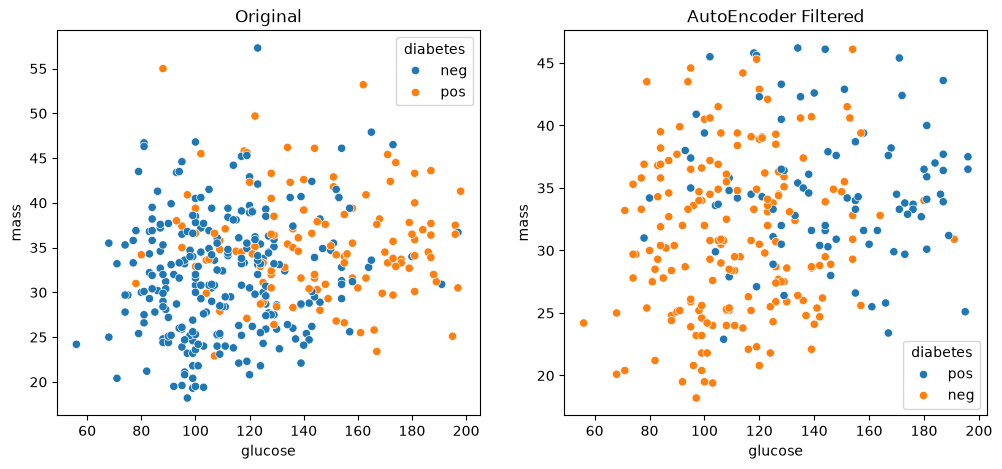

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(df, x="glucose", y="mass", hue="diabetes", ax=axes[0])
sns.scatterplot(df_autoencoded, x="glucose", y="mass", hue="diabetes")
# Prevents overlap between graphs
axes[0].set_title("Original")
axes[1].set_title("AutoEncoder Filtered")

# Shows the plots
plt.show()

# Quite similar results!